# 3. Weakly incompatible qubit pairs (Fig. 4)

$m = 10$ qubits, each carrying two observables at angle $\theta$ ($K = 20$). The task is to estimate all
$K$ correlations to accuracy $U = 0.05$ with probability $0.9$ (maximally mixed data). We report the budget
$B_{0.9}$ of each learner relative to the non-physical ideal learner that reads both observables sharply on every copy:

* **grouped**: two sharp contexts, cost factor equal to the cover number $G = 2$;
* **joint**: the joint POVM of Proposition 4 at the threshold sharpness, predicted cost $\kappa(\theta) = 1 + \sin\theta$.

Each $B_{0.9}$ is the mean of three bisections. Outputs: `results/sim_pairs.json`, `figures/fig_pairs.pdf`.
The run uses the paper's seed and is compared with `reference/sim_pairs.json` (the data of the paper figure).

**Run time:** about 2–5 minutes. Set `RECOMPUTE = False` to plot the saved results instead.
Panel (a) uses the SDP values from notebook 1 (`results/sdp_eta_main.json`, or the reference copy).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS, FIGURES, REFERENCE = ROOT / "results", ROOT / "figures", ROOT / "reference"
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)

import time
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from copycost import pairs
from copycost.style import WIDTH, panel, setup

RECOMPUTE = True
SEED = 7                                   # seed of the paper run
THETAS = np.linspace(0, 90, 19)
OUT = RESULTS / "sim_pairs.json"

In [2]:
if RECOMPUTE or not OUT.exists():
    rng = np.random.default_rng(SEED)
    t0 = time.time()
    out = {"theta_deg": THETAS.tolist(), "oracle": [], "grouped": [], "joint": []}
    bo = np.mean([pairs.b90(0, "oracle", rng) for _ in range(3)])
    for th in THETAS:
        t = np.radians(th)
        out["oracle"].append(bo)
        out["grouped"].append(np.mean([pairs.b90(t, "grouped", rng) for _ in range(3)]))
        out["joint"].append(np.mean([pairs.b90(t, "joint", rng) for _ in range(3)]))
        print(f"theta={th:4.1f}  grouped/ideal={out['grouped'][-1] / bo:.3f}  joint/ideal={out['joint'][-1] / bo:.3f}"
              f"  kappa={1 + np.sin(t):.3f}  ({time.time() - t0:.0f} s)", flush=True)
    OUT.write_text(json.dumps(out))
p = json.loads(OUT.read_text())
ref = json.loads((REFERENCE / "sim_pairs.json").read_text())
for k in ("grouped", "joint"):
    rel = np.array(p[k]) / np.array(ref[k]) - 1
    diff = [f"{t:g} deg ({x:+.1%})" for t, x in zip(p["theta_deg"], rel) if x != 0]
    print(f"{k:8s}: {len(rel) - len(diff)}/{len(rel)} angles identical to the paper data; differences: {diff or 'none'}")

theta= 0.0  grouped/ideal=1.969  joint/ideal=0.831  kappa=1.000  (0 s)


theta= 5.0  grouped/ideal=1.979  joint/ideal=1.005  kappa=1.087  (1 s)


theta=10.0  grouped/ideal=1.974  joint/ideal=1.111  kappa=1.174  (1 s)


theta=15.0  grouped/ideal=1.985  joint/ideal=1.208  kappa=1.259  (2 s)


theta=20.0  grouped/ideal=1.990  joint/ideal=1.310  kappa=1.342  (2 s)


theta=25.0  grouped/ideal=1.979  joint/ideal=1.378  kappa=1.423  (2 s)


... (10 outputs left out)

theta=80.0  grouped/ideal=1.979  joint/ideal=1.979  kappa=1.985  (7 s)


theta=85.0  grouped/ideal=1.996  joint/ideal=2.001  kappa=1.996  (7 s)


theta=90.0  grouped/ideal=1.985  joint/ideal=1.980  kappa=2.000  (7 s)


grouped : 19/19 angles identical to the paper data; differences: none
joint   : 18/19 angles identical to the paper data; differences: ['90 deg (-0.8%)']


## Figure 4

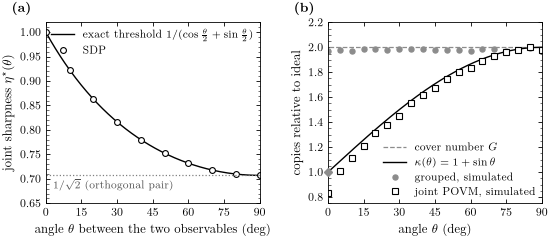

In [3]:
setup()
sdp_file = RESULTS / "sdp_eta_main.json"
s = json.loads((sdp_file if sdp_file.exists() else REFERENCE / "sdp_eta.json").read_text())
th = np.array(p['theta_deg']); o = np.array(p['oracle'])

fig, axs = plt.subplots(1, 2, figsize=(WIDTH, 2.35)); fig.subplots_adjust(wspace=0.32)
ax = axs[0]
tt = np.linspace(0, 90, 400); t = np.radians(tt)
ax.plot(tt, 1 / (np.cos(t / 2) + np.sin(t / 2)), '-', color='0', label=r'exact threshold $1/(\cos\frac{\theta}{2}+\sin\frac{\theta}{2})$')
ax.plot(s['pair']['theta_deg'], s['pair']['eta_sdp'], 'o', mfc='white', mec='0', mew=0.8, ms=4.2, label='SDP')
ax.axhline(1 / np.sqrt(2), color='0.5', ls=':', lw=0.9)
ax.text(3, 1 / np.sqrt(2) - 0.008, r'$1/\sqrt2$ (orthogonal pair)', ha='left', va='top', fontsize=7.5, color='0.3')
ax.set_xlim(0, 90); ax.set_ylim(0.65, 1.02)
ax.xaxis.set_major_locator(MultipleLocator(15)); ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.set_xlabel(r'angle $\theta$ between the two observables (deg)'); ax.set_ylabel(r'joint sharpness $\eta^\star(\theta)$')
ax.legend(loc='upper right', borderaxespad=0.2)
panel(ax, 'a')
ax = axs[1]
ax.plot([0.6, 90], [2, 2], color='0.55', ls='--', lw=0.9, label=r'cover number $G$')
ax.plot([0], [1], marker='D', color='0.55', ms=3.6, ls='none', clip_on=False, zorder=5)
ax.plot(tt, 1 + np.sin(t), '-', color='0', label=r'$\kappa(\theta)=1+\sin\theta$')
ax.plot(th, np.array(p['grouped']) / o, 'o', color='0.55', ms=3.6, label='grouped, simulated')
ax.plot(th, np.array(p['joint']) / o, 's', mfc='white', mec='0', mew=0.8, ms=4.2, label='joint POVM, simulated')
ax.set_xlim(0, 90); ax.set_ylim(0.75, 2.2)
ax.xaxis.set_major_locator(MultipleLocator(15)); ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.set_xlabel(r'angle $\theta$ (deg)'); ax.set_ylabel(r'copies relative to ideal')
ax.legend(loc='lower right', borderaxespad=0.2)
panel(ax, 'b')
fig.savefig(FIGURES / 'fig_pairs.pdf'); fig.savefig(FIGURES / 'fig_pairs.png', dpi=200)
plt.show()

## Numbers quoted in Section 6

In [4]:
tab = pd.DataFrame({"theta_deg": th, "grouped / ideal": np.array(p["grouped"]) / o,
                    "joint / ideal": np.array(p["joint"]) / o, "kappa = 1 + sin(theta)": 1 + np.sin(np.radians(th))})
display(tab.style.format(precision=3))
g = tab["grouped / ideal"]
i20 = int(np.argmin(np.abs(th - 20)))
print(f"grouped / ideal over all angles: {g.min():.2f} to {g.max():.2f}")
print(f"joint / ideal at 20 deg: {tab['joint / ideal'][i20]:.2f} (predicted {tab['kappa = 1 + sin(theta)'][i20]:.2f})")
print(f"joint / ideal at 0 deg: {tab['joint / ideal'][0]:.2f}")

,theta_deg,grouped / ideal,joint / ideal,kappa = 1 + sin(theta)
0,0.000,1.969,0.831,1.000
1,5.000,1.979,1.005,1.087
2,10.000,1.974,1.111,1.174
3,15.000,1.985,1.208,1.259
4,20.000,1.990,1.310,1.342
5,25.000,1.979,1.378,1.423
6,30.000,1.985,1.447,1.500
7,35.000,1.985,1.552,1.574
8,40.000,1.985,1.621,1.643
9,45.000,1.979,1.670,1.707


grouped / ideal over all angles: 1.97 to 2.00
joint / ideal at 20 deg: 1.31 (predicted 1.34)
joint / ideal at 0 deg: 0.83
